In [3]:
import os
import time
from copy import deepcopy
from datetime import datetime
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import sys
# import own modules
sys.path.append(r"C:\Users\rjlea\PycharmProjects\TaskSpecificNeuralMechanismsShapeOrientationPerception")
from mytools.analysis import get_mean_data, get_oei_data
from mytools.dframe_tools import to_csv_pkl, change_dframe_colnames
from mytools.os_tools import make_paths
# import model components
from components.general_functions import join_dicts, get_condcombos
from components.run import mocs_task, staircase_task, run
from components.population_code import Params, Tiling, gen_population_code

In [4]:
def set_params(cond_dicty, cardinal_idx, oblique_idx):
    # sets dictys of params for cardinal and oblique populations
    c_dicty = {}
    o_dicty = {}
    for i_param in cond_dicty:
        if not isinstance(cond_dicty[i_param], list):
            continue
        c_dicty[i_param] = cond_dicty[i_param][cardinal_idx]
        o_dicty[i_param] = cond_dicty[i_param][oblique_idx]
    return Params(c_dicty), Params(o_dicty)

In [5]:
'''
Settings
'''
# Script settings (multi processing uses high CPU)
run_type = 'loop'  # 'single' or 'loop' or 'multi_proc'

# Run information
run_tasks = ['con_det', 'ori_dis']  # ['con_det', 'ori_dis', 'ori_id']
run_ori_stds = [0, 45]
run_contrasts = [100]
n_level_reps = 1000
tuning_dist = 'von_mises'
decoders_ori = ['ML', 'PV', 'WTA']  # ['WTA', 'PV', 'ML']
decoders_condet = ['peak', 'sum', 'mag']  # # ['peak', 'sum', 'v_mag', 'distance', 'PV']

In [6]:
'''
Define fixed model parameters
'''
# Response defaults
fixed_params = {
    'pref_range': 45,
    'noise_type': 'poisson',
    'pref_distrib': 'cos',
    'param_distrib': 'cos',
    'crf_exponent': 2,
    'crf_c50': 24,
    'spont': 3,
}
# Orientation space
orispace = Tiling(-90, 90, step_size=0.05)


In [7]:
'''
Define orientation anisotropies so that cardinal and oblique neurons have different response parameters
'''

# To achieve this, we define the peak value for each parameter
# Let's consider a model with anisotropic orientation bandwidths
cardinal =  Params({
    'n_prefs': 3,  # Defines the number of neurons for each boundary (e.g., from -22.5 to 22.5)
    'fwhm': 57.6 * 0.5,
    'rmax': 60,
    'noise_scale': 1,
    **fixed_params
})
oblique = Params({
    'n_prefs': 3,
    'fwhm': 57.6,
    'rmax': 60,
    'noise_scale': 1,
    **fixed_params
})

model = gen_population_code(cardinal, oblique, orispace,
                            g_params={'tuning_dist': tuning_dist,
                                      'pooling_q': 6})

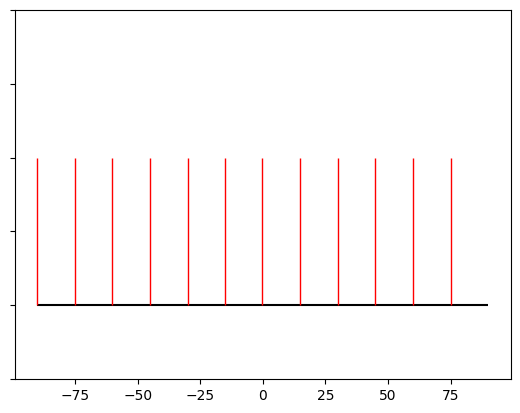

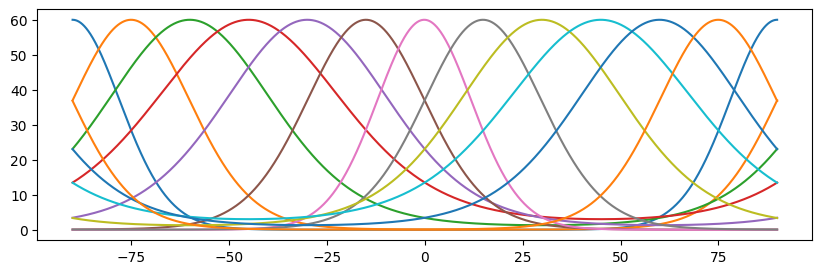

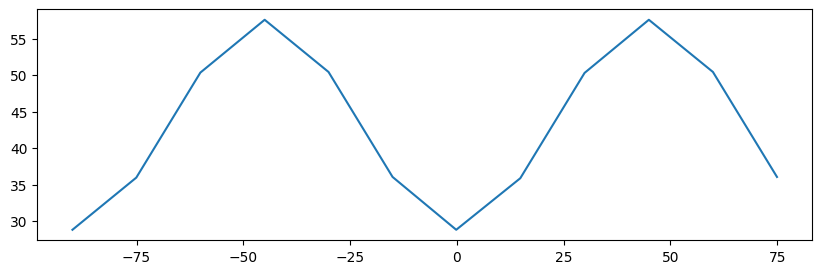

In [8]:
# Show preferences of each neuron
fig, ax = plt.subplots()
ax.hlines(0, xmin=-90, xmax=90, color='black')
ax.vlines(model.prefs, ymin=0, ymax=1, color='red', linewidth=1, zorder=5)
ax.set_ylim(-0.5, 2)
ax.set_yticklabels([])

# The tuning curves of each neuron has been set up according to the defined parameters
fig, ax = plt.subplots(figsize=(10, 3))
plt.plot(orispace.tiling, model.all_tunings.T)

# We can see how the anisotropic parameters vary across orientation space
fig, ax = plt.subplots(figsize=(10, 3))
plt.plot(orispace.tiling[model.prefs_idx], model.param_distribs['fwhm'])


In [12]:
'''
Simulating model responses and task performance
'''
# On each trial, noise is added to the tuned response for a given orientation
stim_ori = 0
stim_ori_idx = np.argmin(abs(orispace.tiling - stim_ori))
print(orispace.tiling)
display(stim_ori_idx)
noisy_response = model.gen_response(stim_ori_idx, stim_contrast=100, n_reps=100)
# Returns noisy response of all neurons to that orientation
fig, ax = plt.subplots(figsize=(8, 4))
plt.plot(model.prefs, noisy_response)

[-90.   -89.95 -89.9  ...  89.9   89.95  90.  ]


np.int64(1800)

TypeError: 'NoneType' object is not subscriptable

In [ ]:

# Define orientation anisotropies
params = {
    'cardinal': {
        'deg_per_pref': [None],  # IGNORE # deg per pref
        'n_prefs': [12],
        'fwhm': [
           np.round(_i * _j, 2) for _i in [57.6, 30.4, 22.2]
           for _j in [1, 0.5]
        ],  # full-width half-max of gaussian tuning mod_orispace
        'pref_distrib': [f"cos"],  # ['flat', 'cos', f'gauss_{sigma}']
        'param_distrib': [f"cos"],  # 0['flat', 'cos', f'gauss_{sigma}']
        'rmax': [60],  # max firing rate (Shen et al., 2014)
        'spont': [3],  # spontaneous firing rate (used to be 0.03 * rmax, now a constant)
        'noise_scale': [1],  # scalar of poisson-like noise
        'crf_exponent': [2],  # 2
        'crf_c50': [24],  # 24
        'pooling_extent': [10],  # used if distance-weighted pooling implemented (units=sigma)
        },
    'oblique': {
        'deg_per_pref': [None],  # IGNORE # deg per pref
        'n_prefs': [12],  # [45, 36, 27, 18, 10]
        # 'n_prefs': [135, 89],
        # 'n_prefs': [270, 180],
        'fwhm': [
          _i for _i in [57.6, 30.4, 22.2]
          for _ in range(2)
        ],
        'pref_distrib': ["cos"],
        'param_distrib': ["cos"],  # distrib of deg / pref across space
        'rmax': [60],
        'spont': [3],  # spontaneous firing rate (used to be 0.03 * rmax)
        'noise_scale': [1],  # scalar
        'crf_exponent': [2],  # 2
        'crf_c50': [24],  # 24
        'pooling_extent': [10],  # used if distance-weighted pooling implemented (units = sigma)
        },
        'pooling': {
            'method': ['sum'],  # todo check functionality (may not be used)
             'exponent': [1],
             'q': [6],
             'pooling_extent': [None]
        }
}
